# 05 – Analyse de survie : combien de temps une machine va-t-elle tenir ?

**Objectif :** estimer la **durée de vie** des machines et la façon dont le **risque de panne augmente avec l'âge**, en tenant compte des **données censurées** (machines qui tournaient encore à la fin de l'observation).

**Pourquoi la survie plutôt qu'une régression classique ?** Si on ignorait les machines encore en marche (censurées), on sous-estimerait la durée de vie. La survie utilise l'information « elle a tenu au moins X heures ».

**Entrée :** `data/synthetic/survival.csv` (1 ligne = 1 cycle de vie : `duration_h`, `event` 1 = panne / 0 = censuré, `machine_type`, `load`).
**Sorties :** `reports/tables/resultats_survie.csv`, `reports/figures/survie_*.png`.

In [5]:
import math, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, WeibullFitter, CoxPHFitter, WeibullAFTFitter
from lifelines.statistics import multivariate_logrank_test

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from generate_data import MACHINE_TYPES      # vraies lois (beta, eta...) : uniquement pour VÉRIFIER

(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
(ROOT / "reports/tables").mkdir(parents=True, exist_ok=True)

## 1. Les données

In [6]:
surv = pd.read_csv(ROOT / "data/synthetic/survival.csv")
surv = surv[surv.duration_h > 0].copy()
surv["log_load"] = np.log(surv["load"])      # la charge agit de façon multiplicative -> on prend le log

print(f"{len(surv)} cycles, {int(surv.event.sum())} pannes observées, "
      f"{int((1 - surv.event).sum())} censurés ({1 - surv.event.mean():.0%})")
surv.groupby("machine_type").agg(cycles=("event", "size"), pannes=("event", "sum"),
                                 duree_moyenne_h=("duration_h", "mean")).round(0)

227 cycles, 169 pannes observées, 58 censurés (26%)


,cycles,pannes,duree_moyenne_h
machine_type,,,
broyeur,94,74,1666.0
compresseur,63,45,2508.0
ventilateur,70,50,2254.0


## 2. Kaplan-Meier : la courbe de survie sans hypothèse

`S(t)` = probabilité qu'une machine **dépasse** `t` heures sans panne. On la trace par type de machine et on teste avec le **log-rank** si les courbes diffèrent vraiment.

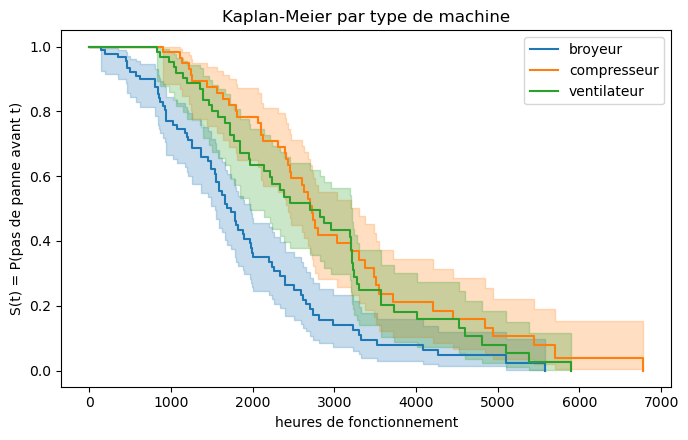

Test log-rank : p = 9e-06  ->  les types ont des durées de vie différentes


broyeur        1740.0
compresseur    2721.0
ventilateur    2701.0
Name: durée de vie médiane (h), dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
km = {}
for mtype, g in surv.groupby("machine_type"):
    km[mtype] = KaplanMeierFitter().fit(g.duration_h, g.event, label=mtype)
    km[mtype].plot_survival_function(ax=ax, ci_show=True)
ax.set_xlabel("heures de fonctionnement"); ax.set_ylabel("S(t) = P(pas de panne avant t)")
ax.set_title("Kaplan-Meier par type de machine")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/survie_kaplan_meier.png", dpi=150); plt.show()

lr = multivariate_logrank_test(surv.duration_h, surv.machine_type, surv.event)
print(f"Test log-rank : p = {lr.p_value:.2g}  ->  "
      f"{'les types ont des durées de vie différentes' if lr.p_value < 0.05 else 'pas de différence nette'}")
pd.Series({k: v.median_survival_time_ for k, v in km.items()}, name="durée de vie médiane (h)").round(0)

## 3. Weibull par type : le risque augmente avec l'âge

La loi de Weibull a deux paramètres : l'**échelle** λ (durée de vie « typique ») et la **forme** ρ :
- ρ < 1 : risque qui **baisse** (pannes de jeunesse),
- ρ = 1 : risque **constant** (pannes aléatoires, la maintenance préventive est inutile),
- ρ > 1 : risque qui **monte** avec l'âge (**usure** : la maintenance préventive a un sens).

Comme on a généré les données, on compare avec la vraie forme `beta`.

In [8]:
wb = {}
rows = []
for mtype, g in surv.groupby("machine_type"):
    w = WeibullFitter().fit(g.duration_h, g.event, label=mtype)
    wb[mtype] = w
    s = w.summary
    rows.append({"type": mtype,
                 "forme ρ estimée": s.loc["rho_", "coef"],
                 "IC95 % ρ": f"[{s.loc['rho_', 'coef lower 95%']:.2f} ; {s.loc['rho_', 'coef upper 95%']:.2f}]",
                 "forme vraie (beta)": MACHINE_TYPES[mtype][0],
                 "échelle λ estimée (h)": s.loc["lambda_", "coef"],
                 "échelle vraie (eta, h)": MACHINE_TYPES[mtype][1]})
weib = pd.DataFrame(rows).set_index("type").round(2)
weib

,forme ρ estimée,IC95 % ρ,forme vraie (beta),échelle λ estimée (h),"échelle vraie (eta, h)"
type,,,,,
broyeur,1.77,[1.47 ; 2.07],2.2,2196.06,1800
compresseur,2.36,[1.86 ; 2.85],3.0,3440.04,3000
ventilateur,2.33,[1.86 ; 2.81],2.6,3137.05,2400


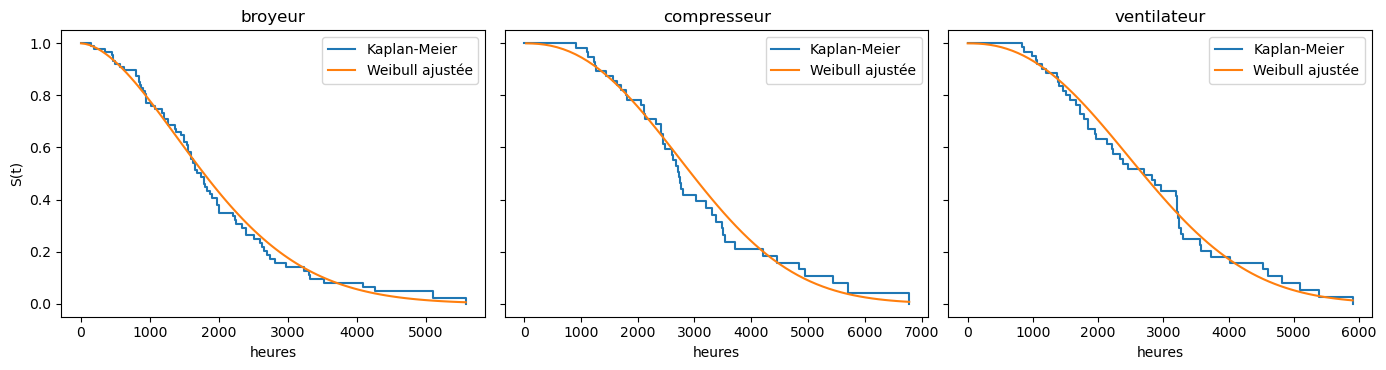

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, mtype in zip(axes, km):
    km[mtype].plot_survival_function(ax=ax, ci_show=False, label="Kaplan-Meier")
    wb[mtype].plot_survival_function(ax=ax, ci_show=False, label="Weibull ajustée")
    ax.set_title(mtype); ax.set_xlabel("heures")
axes[0].set_ylabel("S(t)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/survie_weibull_vs_km.png", dpi=150); plt.show()

**Lecture :**
- Les formes estimées sont toutes **> 1** : le risque monte avec l'âge, c'est bien de l'usure. Aucun type n'a un risque constant.
- Elles sont pourtant **plus faibles que les vraies** (ex. broyeur 1,8 au lieu de 2,2). C'est un vrai phénomène : les machines n'ont pas toutes la même charge ni la même échelle, et mélanger des durées de vie hétérogènes **aplatit** la courbe. Une Weibull « globale » sous-estime donc la forme ; avec la charge dans le modèle (section 5), ρ ≈ 2,2.
- Les échelles estimées sont **plus grandes que les `eta` vrais** : `eta` correspond à une charge de 1, or la charge réelle est comprise entre 0,6 et 1 et **allonge** la durée de vie.

## 4. Cox : quel est l'effet de la charge et du type ?

Le modèle de Cox estime un **hazard ratio** (HR) par covariable : HR > 1 = risque de panne plus élevé. On regroupe par machine (`cluster_col`) car les cycles d'une même machine ne sont pas indépendants.

In [10]:
X = pd.get_dummies(surv[["duration_h", "event", "log_load", "machine_type", "machine_id"]],
                   columns=["machine_type"], drop_first=True, dtype=float)
cph = CoxPHFitter().fit(X, "duration_h", "event", cluster_col="machine_id")
print(f"Indice de concordance (C-index) : {cph.concordance_index_:.3f}   (0,5 = hasard, 1 = parfait)")
hr10 = np.exp(cph.params_["log_load"] * np.log(1.10))
print(f"Une charge +10 % multiplie le risque de panne par {hr10:.2f} (soit +{hr10 - 1:.0%}).")
print("(Référence des types : broyeur. Un HR < 1 = machine plus durable que le broyeur.)")
cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)

Indice de concordance (C-index) : 0.672   (0,5 = hasard, 1 = parfait)
Une charge +10 % multiplie le risque de panne par 1.37 (soit +37%).
(Référence des types : broyeur. Un HR < 1 = machine plus durable que le broyeur.)


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
log_load,27.491,8.690,86.967,0.0
machine_type_compresseur,0.407,0.260,0.637,0.0
machine_type_ventilateur,0.528,0.375,0.744,0.0


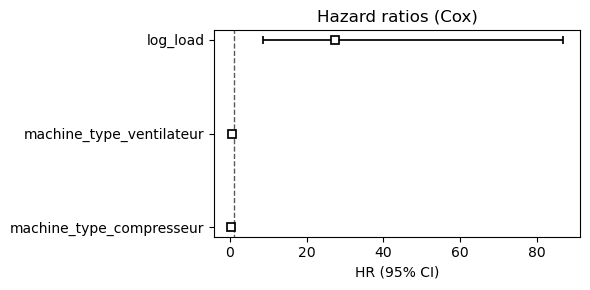

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
cph.plot(hazard_ratios=True, ax=ax)
ax.set_title("Hazard ratios (Cox)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/survie_cox_hazard_ratios.png", dpi=150); plt.show()

## 5. Weibull AFT : prédire la durée de vie d'une machine donnée

Le modèle **AFT** (*accelerated failure time*) dit : « telle covariable **multiplie** la durée de vie par tel facteur ». Dans notre génération, `durée = eta / charge × aléa`, donc le coefficient de `log_load` doit valoir **−1** (une charge ×2 divise la vie par 2).

In [12]:
aft = WeibullAFTFitter().fit(X.drop(columns="machine_id"), "duration_h", "event")
s = aft.summary
coef_load = s.loc[("lambda_", "log_load"), "coef"]
lo, hi = s.loc[("lambda_", "log_load"), "coef lower 95%"], s.loc[("lambda_", "log_load"), "coef upper 95%"]
print(f"Coefficient de log(charge) : {coef_load:.2f}   IC95 % [{lo:.2f} ; {hi:.2f}]   (valeur vraie : -1)")
print(f"C-index : {aft.concordance_index_:.3f}")
print(f"Forme de Weibull (avec la charge dans le modèle) : rho = {np.exp(s.loc[('rho_', 'Intercept'), 'coef']):.2f}")
s[["coef", "coef lower 95%", "coef upper 95%", "p"]].round(3)

Coefficient de log(charge) : -1.50   IC95 % [-2.01 ; -0.99]   (valeur vraie : -1)
C-index : 0.671
Forme de Weibull (avec la charge dans le modèle) : rho = 2.24


coef  coef lower 95%  coef upper 95%    p
param   covariate                                                           
lambda_ log_load                 -1.500          -2.012          -0.988  0.0
        machine_type_compresseur  0.400           0.234           0.565  0.0
        machine_type_ventilateur  0.286           0.126           0.447  0.0
        Intercept                 7.406           7.264           7.548  0.0
rho_    Intercept                 0.808           0.696           0.921  0.0

**Lecture :** le signe est le bon (plus de charge = vie plus courte), mais l'estimation est **plus forte** que la vraie valeur (−1) et celle-ci est tout juste au bord de l'intervalle. Deux raisons : la charge ne varie que sur 0,6–1 (peu d'information) et ce modèle **ignore** que les cycles d'une même machine sont liés, donc l'intervalle est un peu trop étroit. On retient « la charge raccourcit nettement la vie », pas la valeur exacte du coefficient.

## 6. Durée de vie restante (RUL) selon l'âge actuel

Pour une machine donnée qui a déjà tenu `a` heures, on calcule la **durée de vie restante médiane** : on utilise `S(a + t) / S(a)`, la probabilité de tenir encore `t` heures **sachant qu'elle a tenu `a` heures**.

In [13]:
def rul_median(model, row, age, grid=np.arange(0, 8000, 10)):
    S = model.predict_survival_function(row, times=age + grid).iloc[:, 0].values
    S0 = model.predict_survival_function(row, times=[age]).iloc[0, 0]
    cond = S / S0
    below = np.where(cond <= 0.5)[0]
    return grid[below[0]] if len(below) else np.nan

cols = [c for c in X.columns if c not in ("duration_h", "event", "machine_id")]  # covariables du modèle
def profile(mtype, load):
    r = pd.DataFrame(0.0, index=[0], columns=cols)
    r["log_load"] = np.log(load)
    if f"machine_type_{mtype}" in cols:
        r[f"machine_type_{mtype}"] = 1.0
    return r

rows = []
for mtype in MACHINE_TYPES:
    for load in (0.7, 1.0):
        rows.append({"type": mtype, "charge": load,
                     **{f"RUL médiane à {a} h": rul_median(aft, profile(mtype, load), a)
                        for a in (0, 1000, 1500)}})
pd.DataFrame(rows).set_index(["type", "charge"])

RUL médiane à 0 h  RUL médiane à 1000 h  \
type        charge                                            
ventilateur 0.7                  3180                  2290   
            1.0                  1870                  1060   
broyeur     0.7                  2390                  1540   
            1.0                  1400                   670   
compresseur 0.7                  3560                  2650   
            1.0                  2090                  1260   

                    RUL médiane à 1500 h  
type        charge                        
ventilateur 0.7                     1930  
            1.0                      810  
broyeur     0.7                     1240  
            1.0                      480  
compresseur 0.7                     2280  
            1.0                      990

Lecture : une machine **qui a déjà tenu longtemps** a une durée de vie restante **plus courte** (usure, ρ > 1). Une machine à forte charge a une RUL plus courte à âge égal.

## 7. Première règle de maintenance préventive (lien avec l'étude de coût)

Si on remplace une machine à l'âge `T` **avant** qu'elle tombe en panne, on évite le coût d'une panne. Mais remplacer trop tôt gaspille de la vie utile. Le **coût moyen par heure** d'une politique « remplacement à l'âge T » est :

`coût/h (T) = [ Cp · S(T) + Cc · (1 − S(T)) ] / ∫₀ᵀ S(t) dt`

avec `Cp` = coût d'une intervention préventive, `Cc` = coût d'une panne (arrêt de production inclus). On cherche le `T` qui minimise ce coût.

 **Hypothèse à confirmer avec le cas d'usage** : on prend ici `Cc = 8 × Cp` (valeur illustrative). L'étude de coût finale devra utiliser des coûts justifiés.

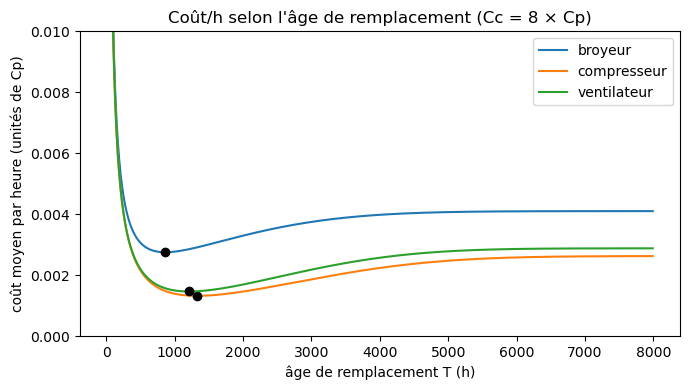

,âge optimal de remplacement T* (h),coût/h à T*,coût/h sans préventif,économie
type,,,,
broyeur,860,0.00275,0.00409,33%
compresseur,1330,0.00133,0.00262,49%
ventilateur,1210,0.00147,0.00288,49%


In [14]:
CP, CC = 1.0, 8.0          # coûts relatifs (ILLUSTRATIFS) : une panne coûte 8x une préventive
t = np.arange(10, 8000, 10)

def cost_rate(w, T_grid=t):
    S = np.exp(-(T_grid / w.lambda_) ** w.rho_)                       # S(t) de Weibull
    area = np.cumsum(S) * 10                                          # intégrale de S par somme
    return (CP * S + CC * (1 - S)) / area

fig, ax = plt.subplots(figsize=(7, 4))
rows = []
for mtype, w in wb.items():
    c = cost_rate(w)
    i = np.argmin(c)
    mean_life = w.lambda_ * math.gamma(1 + 1 / w.rho_)
    run_to_failure = CC / mean_life                  # coût/h si on attend toujours la panne
    ax.plot(t, c, label=mtype); ax.plot(t[i], c[i], "ko")
    rows.append({"type": mtype, "âge optimal de remplacement T* (h)": t[i],
                 "coût/h à T*": round(c[i], 5),
                 "coût/h sans préventif": round(run_to_failure, 5),
                 "économie": f"{1 - c[i] / run_to_failure:.0%}"})
ax.set_xlabel("âge de remplacement T (h)"); ax.set_ylabel("coût moyen par heure (unités de Cp)")
ax.set_ylim(0, 0.01); ax.legend(); ax.set_title(f"Coût/h selon l'âge de remplacement (Cc = {CC:.0f} × Cp)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/survie_cout_age_optimal.png", dpi=150); plt.show()
opt = pd.DataFrame(rows).set_index("type")
opt

## 8. Sauvegarde

In [15]:
out = weib.join(opt)
out.to_csv(ROOT / "reports/tables/resultats_survie.csv")
out

,forme ρ estimée,IC95 % ρ,forme vraie (beta),échelle λ estimée (h),"échelle vraie (eta, h)",âge optimal de remplacement T* (h),coût/h à T*,coût/h sans préventif,économie
type,,,,,,,,,
broyeur,1.77,[1.47 ; 2.07],2.2,2196.06,1800,860,0.00275,0.00409,33%
compresseur,2.36,[1.86 ; 2.85],3.0,3440.04,3000,1330,0.00133,0.00262,49%
ventilateur,2.33,[1.86 ; 2.81],2.6,3137.05,2400,1210,0.00147,0.00288,49%
